# Module 7. Topic 14. Regularization and hyperparameter optimization

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BetterED-Neoversity/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/blob/main/notebooks/Module_7_Lecture_14_Class.ipynb)

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import matplotlib.pyplot as plt

# Normalization techniques

In [2]:
# define transformations for the data
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # mean and standard deviation for MNIST
])

# download the complete MNIST data set
full_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

# split the data set into training and validation
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# create a test data set
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# determine the batch size
batch_size = 64

# create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train set size: {len(train_dataset)}")
print(f"Validation set size: {len(val_dataset)}")
print(f"Test set size: {len(test_dataset)}")
print(f"Number of batches in train_loader: {len(train_loader)}")

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<00:42, 235kB/s]

  1%|          | 98.3k/9.91M [00:00<00:26, 374kB/s]

  2%|▏         | 164k/9.91M [00:00<00:33, 290kB/s] 

  3%|▎         | 328k/9.91M [00:00<00:16, 569kB/s]

  6%|▌         | 590k/9.91M [00:00<00:09, 975kB/s]

... (32 outputs left out)

100%|██████████| 1.65M/1.65M [00:01<00:00, 1.30MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 17.4MB/s]

Train set size: 48000
Validation set size: 12000
Test set size: 10000
Number of batches in train_loader: 750


In [3]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 512)
        self.fc3 = nn.Linear(512, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

In [4]:
# no regularization

model = Net()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

num_epochs = 20

train_losses = []
train_accs = []

val_losses = []
val_accs = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data.view(data.size(0), -1))
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, predicted = output.max(1)
        train_total += target.size(0)
        train_correct += predicted.eq(target).sum().item()

    train_loss /= len(train_loader)
    train_accuracy = 100. * train_correct / train_total
    
    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    # validation step
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for data, target in val_loader:
            output = model(data.view(data.size(0), -1))
            loss = criterion(output, target)
            val_loss += loss.item()
            _, predicted = output.max(1)
            val_total += target.size(0)
            val_correct += predicted.eq(target).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100. * val_correct / val_total
    
    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    print(f'Epoch [{epoch+1}/{num_epochs}]')
    print(f'Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%')
    print(f'Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%')
    print('-' * 50)

Epoch [1/20]
Train Loss: 0.2158, Train Accuracy: 93.38%
Val Loss: 0.1197, Val Accuracy: 96.58%
--------------------------------------------------


Epoch [2/20]
Train Loss: 0.0928, Train Accuracy: 97.17%
Val Loss: 0.1029, Val Accuracy: 97.10%
--------------------------------------------------


Epoch [3/20]
Train Loss: 0.0670, Train Accuracy: 97.87%
Val Loss: 0.0970, Val Accuracy: 97.09%
--------------------------------------------------


Epoch [4/20]
Train Loss: 0.0502, Train Accuracy: 98.42%
Val Loss: 0.1035, Val Accuracy: 97.10%
--------------------------------------------------


Epoch [5/20]
Train Loss: 0.0425, Train Accuracy: 98.63%
Val Loss: 0.0955, Val Accuracy: 97.38%
--------------------------------------------------


Epoch [6/20]
Train Loss: 0.0321, Train Accuracy: 98.92%
Val Loss: 0.1450, Val Accuracy: 96.97%
--------------------------------------------------


... (10 outputs left out)

Epoch [17/20]
Train Loss: 0.0189, Train Accuracy: 99.48%
Val Loss: 0.1357, Val Accuracy: 97.76%
--------------------------------------------------


Epoch [18/20]
Train Loss: 0.0115, Train Accuracy: 99.67%
Val Loss: 0.1750, Val Accuracy: 97.33%
--------------------------------------------------


Epoch [19/20]
Train Loss: 0.0212, Train Accuracy: 99.39%
Val Loss: 0.1563, Val Accuracy: 97.81%
--------------------------------------------------


Epoch [20/20]
Train Loss: 0.0117, Train Accuracy: 99.71%
Val Loss: 0.1863, Val Accuracy: 97.71%
--------------------------------------------------


In [5]:
def visualize_training_history(train_losses, train_accs, val_losses, val_accs):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(12, 5))

    # loss plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, 'b-', label='Train Loss')
    plt.plot(epochs, val_losses, 'r-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # accuracy plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accs, 'b-', label='Train Accuracy')
    plt.plot(epochs, val_accs, 'r-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

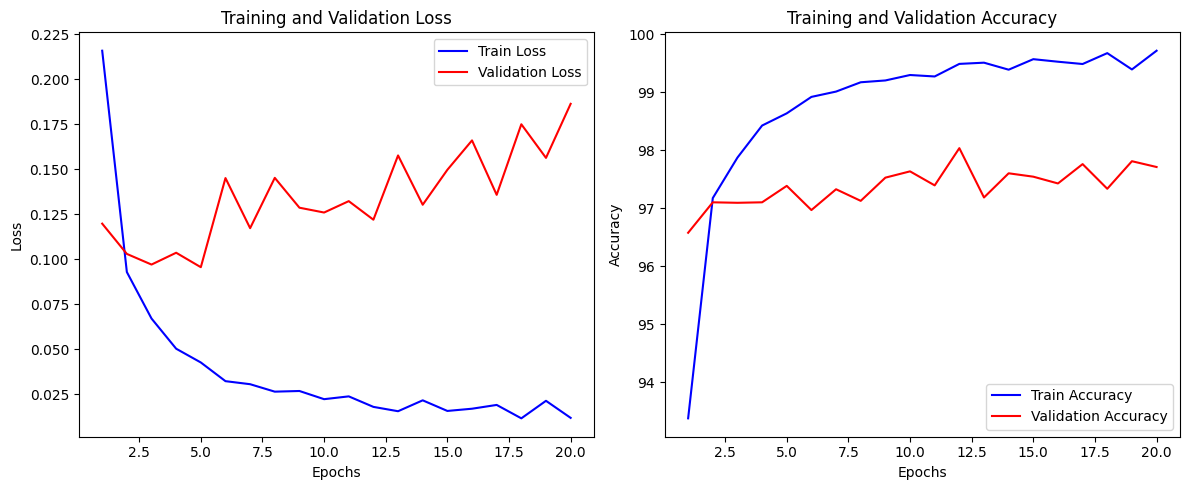

In [6]:
visualize_training_history(train_losses, train_accs, val_losses, val_accs)

Epoch [1/20]
Train Loss: 0.2314, Train Accuracy: 92.96%
Val Loss: 0.1344, Val Accuracy: 95.94%
--------------------------------------------------


Epoch [2/20]
Train Loss: 0.1149, Train Accuracy: 96.46%
Val Loss: 0.1121, Val Accuracy: 96.70%
--------------------------------------------------


Epoch [3/20]
Train Loss: 0.0932, Train Accuracy: 97.03%
Val Loss: 0.1049, Val Accuracy: 96.78%
--------------------------------------------------


Epoch [4/20]
Train Loss: 0.0823, Train Accuracy: 97.43%
Val Loss: 0.0904, Val Accuracy: 97.22%
--------------------------------------------------


Epoch [5/20]
Train Loss: 0.0737, Train Accuracy: 97.67%
Val Loss: 0.1228, Val Accuracy: 96.25%
--------------------------------------------------


Epoch [6/20]
Train Loss: 0.0688, Train Accuracy: 97.84%
Val Loss: 0.1064, Val Accuracy: 96.84%
--------------------------------------------------


... (10 outputs left out)

Epoch [17/20]
Train Loss: 0.0452, Train Accuracy: 98.57%
Val Loss: 0.0973, Val Accuracy: 97.02%
--------------------------------------------------


Epoch [18/20]
Train Loss: 0.0452, Train Accuracy: 98.54%
Val Loss: 0.1101, Val Accuracy: 96.61%
--------------------------------------------------


Epoch [19/20]
Train Loss: 0.0445, Train Accuracy: 98.63%
Val Loss: 0.0931, Val Accuracy: 97.26%
--------------------------------------------------


Epoch [20/20]
Train Loss: 0.0460, Train Accuracy: 98.53%
Val Loss: 0.1015, Val Accuracy: 97.08%
--------------------------------------------------


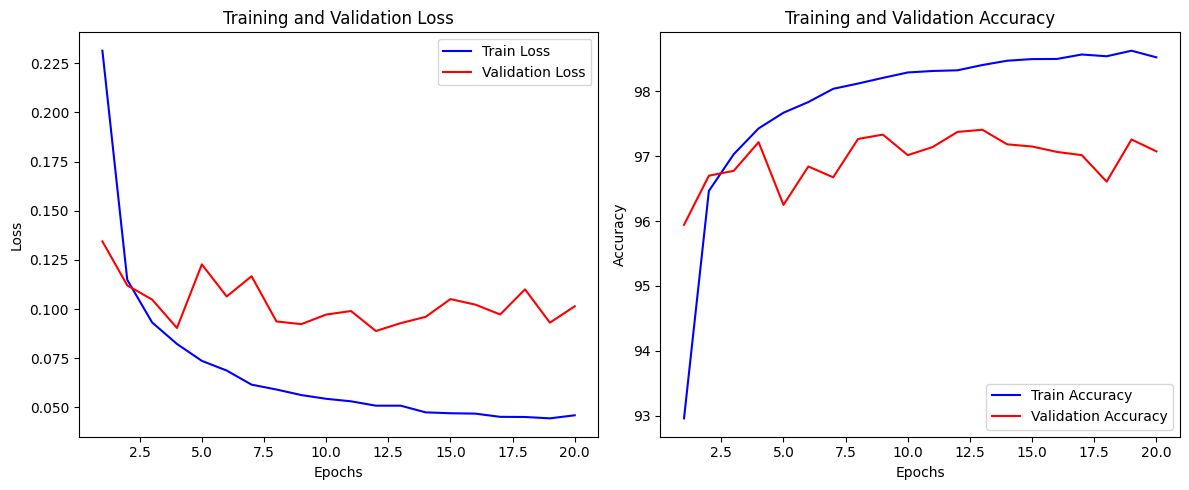

In [7]:
# L2 regularization

model = Net()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), weight_decay=1e-3)

num_epochs = 20

train_losses = []
train_accs = []

val_losses = []
val_accs = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data.view(data.size(0), -1))
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, predicted = output.max(1)
        train_total += target.size(0)
        train_correct += predicted.eq(target).sum().item()

    train_loss /= len(train_loader)
    train_accuracy = 100. * train_correct / train_total
    
    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    # validation step
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for data, target in val_loader:
            output = model(data.view(data.size(0), -1))
            loss = criterion(output, target)
            val_loss += loss.item()
            _, predicted = output.max(1)
            val_total += target.size(0)
            val_correct += predicted.eq(target).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100. * val_correct / val_total
    
    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    print(f'Epoch [{epoch+1}/{num_epochs}]')
    print(f'Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%')
    print(f'Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%')
    print('-' * 50)
    
visualize_training_history(train_losses, train_accs, val_losses, val_accs)

In [8]:
# early stopping

model = Net()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())
best_val_loss = float('inf')
patience = 2
counter = 0

train_losses = []
train_accs = []
val_losses = []
val_accs = []

for epoch in range(20):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data.view(data.size(0), -1))
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        _, predicted = output.max(1)
        train_total += target.size(0)
        train_correct += predicted.eq(target).sum().item()
    
    train_loss /= len(train_loader)
    train_acc = 100. * train_correct / train_total
    
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for data, target in val_loader:
            output = model(data.view(data.size(0), -1))
            val_loss += criterion(output, target).item()
            _, predicted = output.max(1)
            val_total += target.size(0)
            val_correct += predicted.eq(target).sum().item()
    
    val_loss /= len(val_loader)
    val_acc = 100. * val_correct / val_total
    
    # save results
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    
    print(f'Epoch {epoch}: Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

Epoch 0: Train Loss: 0.2222, Train Acc: 93.07%, Val Loss: 0.1238, Val Acc: 96.33%


Epoch 1: Train Loss: 0.0933, Train Acc: 97.08%, Val Loss: 0.1155, Val Acc: 96.53%


Epoch 2: Train Loss: 0.0630, Train Acc: 98.00%, Val Loss: 0.1056, Val Acc: 97.14%


Epoch 3: Train Loss: 0.0504, Train Acc: 98.35%, Val Loss: 0.1228, Val Acc: 96.67%


Epoch 4: Train Loss: 0.0421, Train Acc: 98.68%, Val Loss: 0.1142, Val Acc: 97.17%
Early stopping at epoch 4


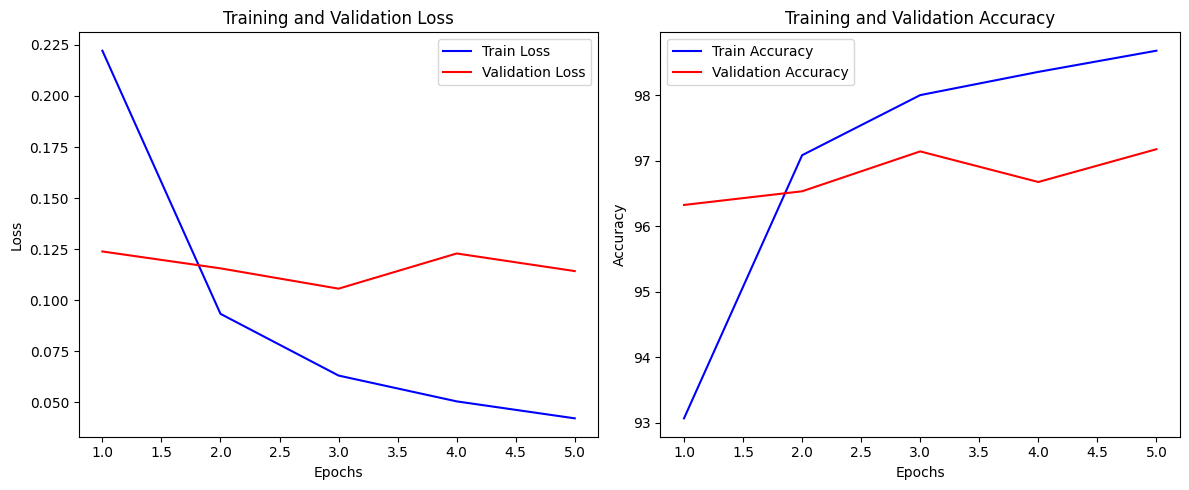

In [9]:
visualize_training_history(train_losses, train_accs, val_losses, val_accs)

In [10]:
class NetWithDropout(nn.Module):
    def __init__(self):
        super(NetWithDropout, self).__init__()
        self.fc1 = nn.Linear(784, 512)
        self.dropout1 = nn.Dropout(0.2)
        self.fc2 = nn.Linear(512, 512)
        self.dropout2 = nn.Dropout(0.2)
        self.fc3 = nn.Linear(512, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.dropout1(x)
        x = torch.relu(self.fc2(x))
        x = self.dropout2(x)
        return self.fc3(x)

In [11]:
# dropout

model = NetWithDropout()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

train_losses = []
train_accs = []
val_losses = []
val_accs = []

for epoch in range(20):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data.view(data.size(0), -1))
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        _, predicted = output.max(1)
        train_total += target.size(0)
        train_correct += predicted.eq(target).sum().item()
    
    train_loss /= len(train_loader)
    train_acc = 100. * train_correct / train_total
    
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for data, target in val_loader:
            output = model(data.view(data.size(0), -1))
            val_loss += criterion(output, target).item()
            _, predicted = output.max(1)
            val_total += target.size(0)
            val_correct += predicted.eq(target).sum().item()
    
    val_loss /= len(val_loader)
    val_acc = 100. * val_correct / val_total
    
    # save results
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    
    print(f'Epoch {epoch}: Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

Epoch 0: Train Loss: 0.2503, Train Acc: 92.24%, Val Loss: 0.1442, Val Acc: 95.39%


Epoch 1: Train Loss: 0.1138, Train Acc: 96.47%, Val Loss: 0.1134, Val Acc: 96.64%


Epoch 2: Train Loss: 0.0911, Train Acc: 97.17%, Val Loss: 0.1026, Val Acc: 96.88%


Epoch 3: Train Loss: 0.0755, Train Acc: 97.56%, Val Loss: 0.0923, Val Acc: 97.22%


Epoch 4: Train Loss: 0.0653, Train Acc: 97.88%, Val Loss: 0.0978, Val Acc: 97.43%


Epoch 5: Train Loss: 0.0611, Train Acc: 98.05%, Val Loss: 0.0949, Val Acc: 97.51%


... (10 outputs left out)

Epoch 16: Train Loss: 0.0344, Train Acc: 99.05%, Val Loss: 0.1192, Val Acc: 97.77%


Epoch 17: Train Loss: 0.0313, Train Acc: 99.05%, Val Loss: 0.1287, Val Acc: 97.83%


Epoch 18: Train Loss: 0.0342, Train Acc: 99.01%, Val Loss: 0.1307, Val Acc: 97.89%


Epoch 19: Train Loss: 0.0368, Train Acc: 99.00%, Val Loss: 0.1443, Val Acc: 97.79%


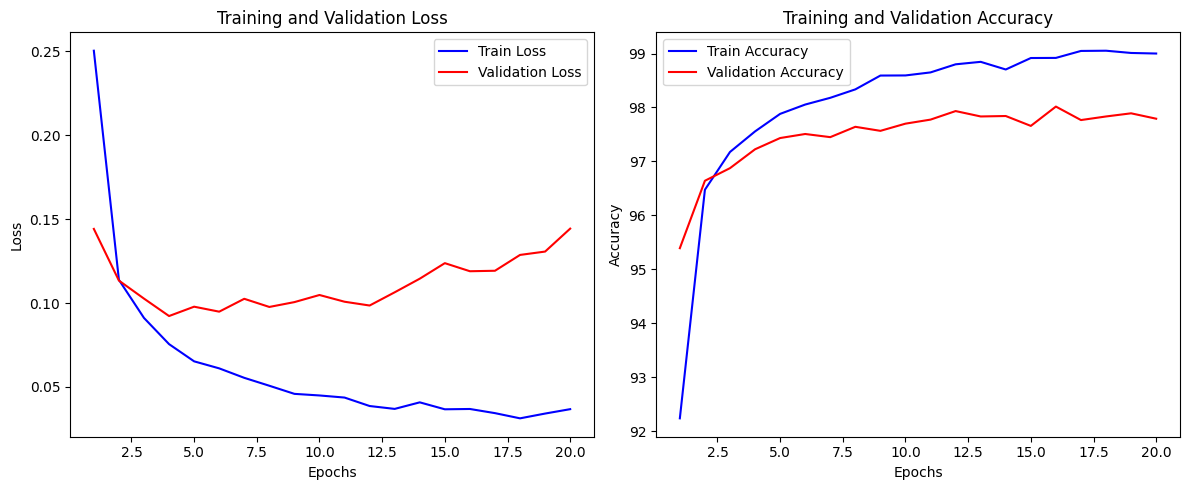

In [12]:
visualize_training_history(train_losses, train_accs, val_losses, val_accs)

In [13]:
class NetWithBN(nn.Module):
    def __init__(self):
        super(NetWithBN, self).__init__()
        self.fc1 = nn.Linear(784, 256)
        self.bn1 = nn.BatchNorm1d(256)
        self.fc2 = nn.Linear(256, 256)
        self.bn2 = nn.BatchNorm1d(256)
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = torch.relu(self.bn1(self.fc1(x)))
        x = torch.relu(self.bn2(self.fc2(x)))
        return self.fc3(x)

Epoch 0: Train Loss: 0.2074, Train Acc: 93.95%, Val Loss: 0.1098, Val Acc: 96.64%


Epoch 1: Train Loss: 0.0871, Train Acc: 97.26%, Val Loss: 0.0917, Val Acc: 97.18%


Epoch 2: Train Loss: 0.0610, Train Acc: 98.11%, Val Loss: 0.0802, Val Acc: 97.72%


Epoch 3: Train Loss: 0.0454, Train Acc: 98.54%, Val Loss: 0.0835, Val Acc: 97.65%


Epoch 4: Train Loss: 0.0382, Train Acc: 98.73%, Val Loss: 0.0838, Val Acc: 97.62%


Epoch 5: Train Loss: 0.0282, Train Acc: 99.09%, Val Loss: 0.0791, Val Acc: 97.78%


... (10 outputs left out)

Epoch 16: Train Loss: 0.0090, Train Acc: 99.70%, Val Loss: 0.0939, Val Acc: 97.87%


Epoch 17: Train Loss: 0.0101, Train Acc: 99.65%, Val Loss: 0.0927, Val Acc: 97.91%


Epoch 18: Train Loss: 0.0102, Train Acc: 99.66%, Val Loss: 0.0901, Val Acc: 98.05%


Epoch 19: Train Loss: 0.0093, Train Acc: 99.67%, Val Loss: 0.0938, Val Acc: 97.96%


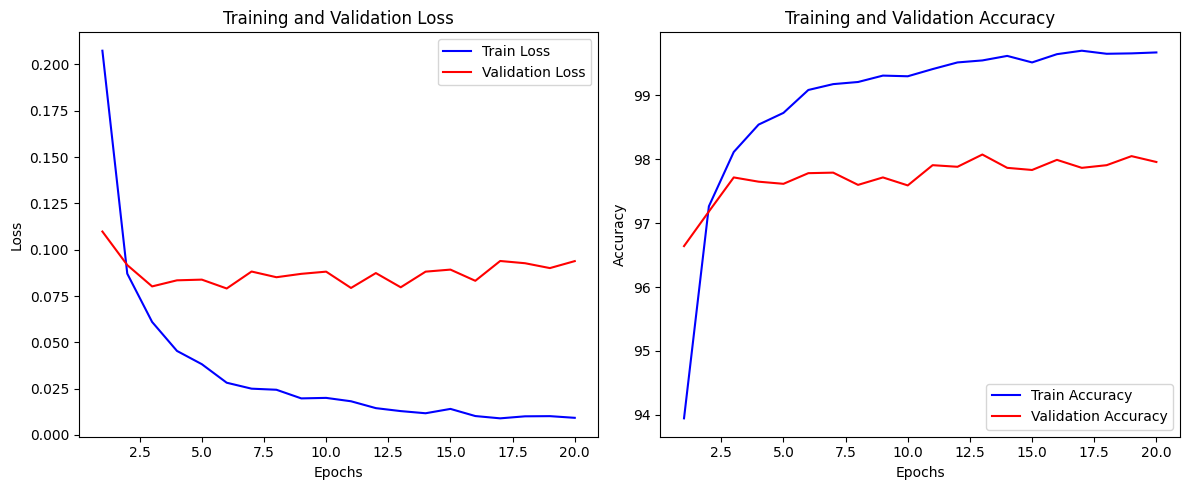

In [14]:
# BN

model = NetWithBN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

train_losses = []
train_accs = []
val_losses = []
val_accs = []

for epoch in range(20):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data.view(data.size(0), -1))
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        _, predicted = output.max(1)
        train_total += target.size(0)
        train_correct += predicted.eq(target).sum().item()
    
    train_loss /= len(train_loader)
    train_acc = 100. * train_correct / train_total
    
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for data, target in val_loader:
            output = model(data.view(data.size(0), -1))
            val_loss += criterion(output, target).item()
            _, predicted = output.max(1)
            val_total += target.size(0)
            val_correct += predicted.eq(target).sum().item()
    
    val_loss /= len(val_loader)
    val_acc = 100. * val_correct / val_total
    
    # save results
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    
    print(f'Epoch {epoch}: Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')
    
    
visualize_training_history(train_losses, train_accs, val_losses, val_accs)

# Hyperparameter optimization

In [15]:
!pip install optuna

import optuna

In [16]:
class Net(nn.Module):
    def __init__(self, dropout_rate, use_batchnorm):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 512)
        self.fc3 = nn.Linear(512, 10)
        self.dropout = nn.Dropout(dropout_rate)
        self.use_batchnorm = use_batchnorm
        if use_batchnorm:
            self.bn1 = nn.BatchNorm1d(512)
            self.bn2 = nn.BatchNorm1d(512)

    def forward(self, x):
        x = x.view(-1, 784)
        x = self.fc1(x)
        if self.use_batchnorm:
            x = self.bn1(x)
        x = torch.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        if self.use_batchnorm:
            x = self.bn2(x)
        x = torch.relu(x)
        x = self.dropout(x)
        return self.fc3(x)

In [17]:
def objective(trial):
    # determine hyperparameters for optimization
    lr = trial.suggest_float('lr', 1e-5, 1e-1, log=True)
    dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5)
    use_batchnorm = trial.suggest_categorical('use_batchnorm', [True, False])
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128, 256])
    
    # create a model with selected hyperparameters
    model = Net(dropout_rate, use_batchnorm)
    
    # training settings
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    
    # model training
    model.train()
    for epoch in range(10):  # let's limit it to 10 epochs for speed
        for batch_idx, (data, target) in enumerate(train_loader):
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
        
        # Early stopping
        if epoch > 2 and loss.item() > prev_loss:
            break
        prev_loss = loss.item()
    
    # model evaluation
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data, target in DataLoader(val_dataset, batch_size=1000):
            output = model(data)
            _, predicted = torch.max(output.data, 1)
            total += target.size(0)
            correct += (predicted == target).sum().item()
    
    accuracy = correct / total
    return accuracy

In [18]:
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)

print('Number of finished trials:', len(study.trials))
print('Best trial:')
trial = study.best_trial
print('  Value: ', trial.value)
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))

[I 2026-11-16 23:28:26,699] A new study created in memory with name: no-name-d9bc33d1-875e-4743-87bc-2850565301d7


[I 2026-11-16 23:29:15,037] Trial 0 finished with value: 0.97475 and parameters: {'lr': 0.025783814047124574, 'dropout_rate': 0.3763674702984853, 'use_batchnorm': True, 'batch_size': 64}. Best is trial 0 with value: 0.97475.


[I 2026-11-16 23:29:47,347] Trial 1 finished with value: 0.9665833333333333 and parameters: {'lr': 7.211296678113857e-05, 'dropout_rate': 0.42383825359912386, 'use_batchnorm': True, 'batch_size': 64}. Best is trial 0 with value: 0.97475.


[I 2026-11-16 23:30:15,219] Trial 2 finished with value: 0.8981666666666667 and parameters: {'lr': 0.012298912399802598, 'dropout_rate': 0.27880761655688624, 'use_batchnorm': False, 'batch_size': 64}. Best is trial 0 with value: 0.97475.


[I 2026-11-16 23:30:52,542] Trial 3 finished with value: 0.9753333333333334 and parameters: {'lr': 0.00207440586514891, 'dropout_rate': 0.12733050321796374, 'use_batchnorm': False, 'batch_size': 128}. Best is trial 3 with value: 0.9753333333333334.


[I 2026-11-16 23:31:29,111] Trial 4 finished with value: 0.9083333333333333 and parameters: {'lr': 1.084496567008479e-05, 'dropout_rate': 0.40961139906613797, 'use_batchnorm': False, 'batch_size': 64}. Best is trial 3 with value: 0.9753333333333334.


... (92 outputs left out)

[I 2026-11-17 00:15:19,799] Trial 97 finished with value: 0.9736666666666667 and parameters: {'lr': 0.0013424401485089862, 'dropout_rate': 0.11247277434914238, 'use_batchnorm': True, 'batch_size': 64}. Best is trial 40 with value: 0.9798333333333333.


[I 2026-11-17 00:15:54,345] Trial 98 finished with value: 0.9793333333333333 and parameters: {'lr': 0.0008415843809955227, 'dropout_rate': 0.25949808261295765, 'use_batchnorm': True, 'batch_size': 64}. Best is trial 40 with value: 0.9798333333333333.


[I 2026-11-17 00:16:14,329] Trial 99 finished with value: 0.9763333333333334 and parameters: {'lr': 0.0013648844142679893, 'dropout_rate': 0.26599785830762473, 'use_batchnorm': True, 'batch_size': 256}. Best is trial 40 with value: 0.9798333333333333.


Number of finished trials: 100
Best trial:
  Value:  0.9798333333333333
  Params: 
    lr: 0.0009407960647593679
    dropout_rate: 0.1807701530444603
    use_batchnorm: True
    batch_size: 64


/tmp/ipykernel_182196/3302522744.py:3: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study)


<Figure size 1000x600 with 0 Axes>

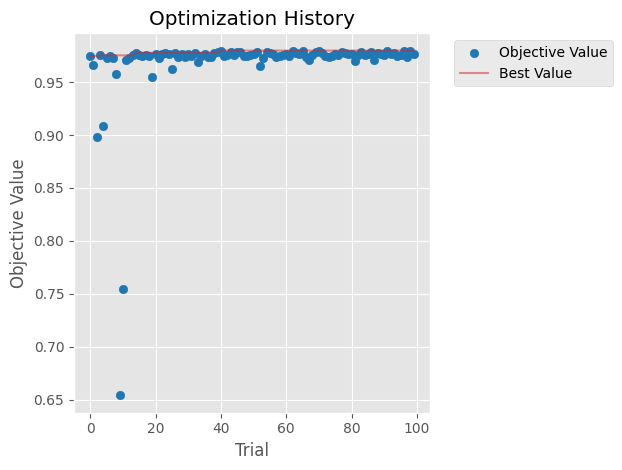

In [19]:
# 1. Optimization history plot
plt.figure(figsize=(10, 6))
optuna.visualization.matplotlib.plot_optimization_history(study)
plt.title("Optimization History")
plt.show()

/tmp/ipykernel_182196/2854606975.py:3: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(study)


<Figure size 1000x600 with 0 Axes>

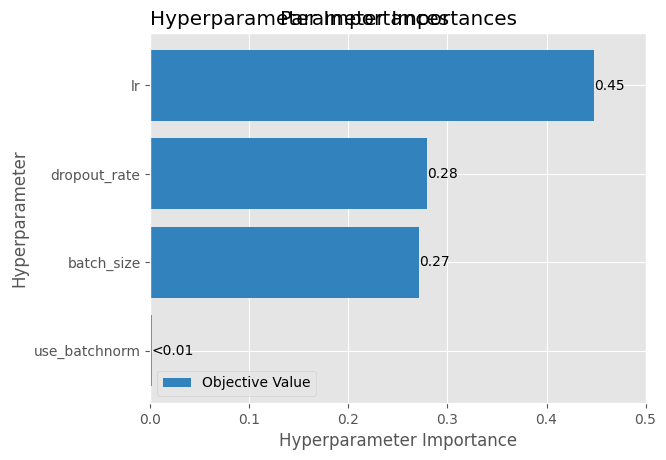

In [20]:
# 2. Parameter importance plot
plt.figure(figsize=(10, 6))
optuna.visualization.matplotlib.plot_param_importances(study)
plt.title("Parameter Importances")
plt.show()

/tmp/ipykernel_182196/4239929850.py:3: ExperimentalWarning: optuna.visualization.matplotlib._parallel_coordinate.plot_parallel_coordinate is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_parallel_coordinate(study)


<Figure size 1000x600 with 0 Axes>

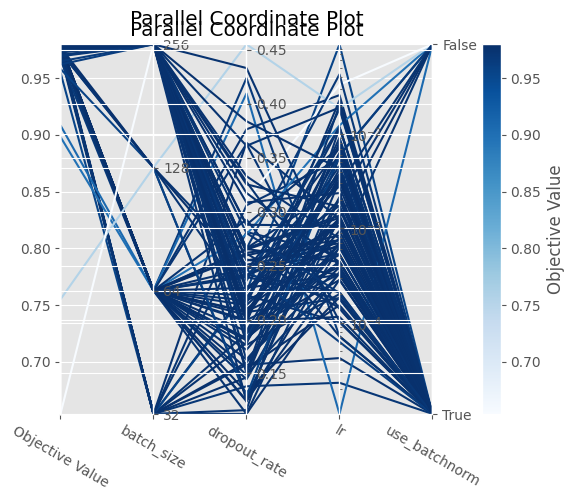

In [21]:
# 3. Parameters interaction plot
plt.figure(figsize=(10, 6))
optuna.visualization.matplotlib.plot_parallel_coordinate(study)
plt.title("Parallel Coordinate Plot")
plt.show()

/tmp/ipykernel_182196/2928570007.py:3: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_slice(study)


<Figure size 1000x600 with 0 Axes>

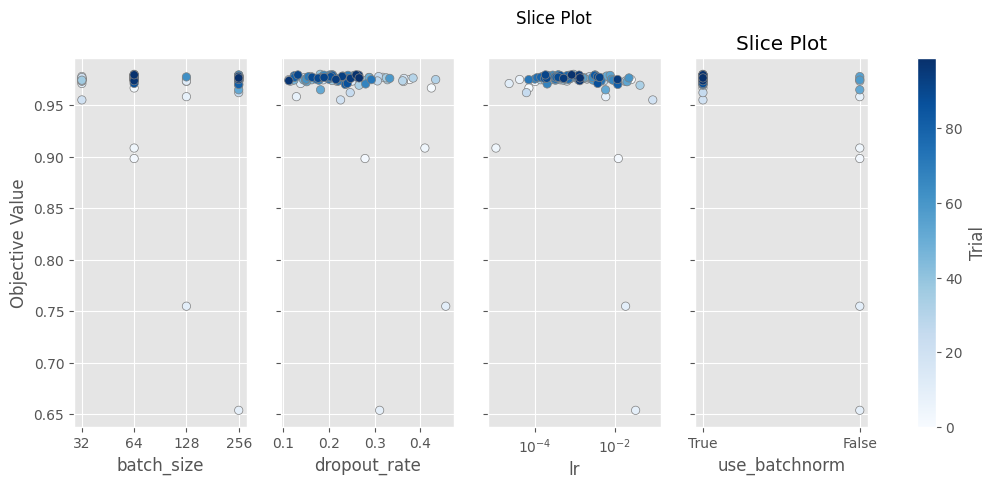

In [22]:
# 4. Parameter value distribution plot
plt.figure(figsize=(10, 6))
optuna.visualization.matplotlib.plot_slice(study)
plt.title("Slice Plot")
plt.show()

In [23]:
# 5. Interactive optimization plot
fig = optuna.visualization.plot_optimization_history(study)
fig.show()

In [24]:
# 6. Interactive parameter importance plot
fig = optuna.visualization.plot_param_importances(study)
fig.show()

In [25]:
# 7. Interactive interaction of parameters plot
fig = optuna.visualization.plot_parallel_coordinate(study)
fig.show()

In [26]:
# 8. Interactive parameter value distribution plot
fig = optuna.visualization.plot_slice(study)
fig.show()